# Clasificación de tumores cerebrales en resonancias magnéticas con redes convolucionales

## Michelle Rergis Novelo | A01798576

**Implementación de un modelo de deep learning**

Dataset: [Brain Tumor MRI Dataset – Kaggle (Msoud Nickparvar)](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset)



> **Cómo ejecutar:** se recomienda Google Colab con GPU (*Entorno de ejecución → Cambiar tipo → GPU*). El dataset se descarga automáticamente con `kagglehub` (en Colab puede pedir credenciales de Kaggle; alternativamente descarga el dataset a mano y apunta `DATA_DIR` a la carpeta).


## 1. Introducción

### Planteamiento del problema
Los tumores cerebrales se detectan y caracterizan principalmente con **resonancia magnética (MRI)**. Interpretar estas imágenes requiere radiólogos especializados, es un proceso lento y su resultado puede variar entre observadores; además, distinguir el tipo de tumor es importante porque cada uno implica un pronóstico y un tratamiento distintos.

El problema que se aborda es de **clasificación de imágenes**: dado un corte de resonancia magnética cerebral, el modelo debe predecir a cuál de **4 categorías** pertenece:

| Clase | Descripción |
|---|---|
| `glioma` | Tumor que se origina en las células gliales (el tejido de soporte del cerebro) |
| `meningioma` | Tumor que se origina en las meninges, las membranas que recubren el cerebro |
| `pituitary` | Tumor en la glándula pituitaria (hipófisis) |
| `notumor` | Cerebro sin tumor visible |

### Relevancia
- **Clínica:** una herramienta de apoyo puede ayudar a **priorizar casos** y ofrecer una "segunda lectura" para reducir omisiones, sobre todo donde hay pocos especialistas.
- **Técnica:** es un problema de visión por computadora realista: las imágenes son en escala de grises, vienen en tamaños y orientaciones diversos, y las clases son visualmente parecidas entre sí (lo que importa son diferencias sutiles de forma, localización y textura).
- **Metodológica:** las consecuencias de un error no son simétricas (no detectar un tumor es mucho más grave que una falsa alarma), por lo que no basta con mirar el *accuracy*: se analizan *recall* por clase y matrices de confusión.

### Enfoque
Las imágenes tienen estructura espacial (bordes, texturas, formas), por lo que se emplean **redes convolucionales (CNN)**, que comparten pesos a lo largo de la imagen y aprenden jerarquías de características. El trabajo se desarrolla de forma iterativa:

1. Un **modelo base** (CNN sencilla) como punto de referencia.
2. Un **modelo mejorado** con aumento de datos, normalización por lotes, regularización (Dropout, L2), pesos de clase y *callbacks*, además de una pequeña búsqueda de hiperparámetros.
3. Un **modelo con transferencia de aprendizaje** (MobileNetV2 preentrenada en ImageNet) con *fine-tuning*.

Se elige el mejor modelo con el conjunto de **validación** y se reporta su desempeño final una sola vez sobre el conjunto de **prueba**.

## 2. Datos

### 2.1 Descripción y fuente
- **Nombre:** Brain Tumor MRI Dataset
- **Autor:** Msoud Nickparvar
- **Fuente:** Kaggle – <https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset> (también publicado en [Zenodo](https://zenodo.org/doi/10.5281/zenodo.12735692) con licencia CC BY 4.0)
- **Contenido:** varios miles de imágenes de resonancia magnética cerebral organizadas en carpetas `Training/` y `Testing/`, con una subcarpeta por clase: `glioma`, `meningioma`, `notumor` y `pituitary`. Según la página del dataset, reúne imágenes de varias fuentes públicas; conviene revisar ahí la descripción y los términos de uso.
- **Por qué cumple los requisitos:** no es un *toy dataset* (imágenes médicas reales, de tamaños variables y con clases sutilmente distintas) y es distinto de los datasets vistos en clase.

### 2.2 Configuración e importación de librerías
Todos los parámetros ajustables se concentran en la siguiente celda.

In [2]:
# Configuración general
SEED = 42
IMG_SIZE = 160            # las imágenes se reescalan a IMG_SIZE x IMG_SIZE
BATCH_SIZE = 32

DATA_DIR = None           # None -> descarga con kagglehub; o pon aquí la ruta a la carpeta del dataset
USE_PRETRAINED = True     # True -> MobileNetV2 con pesos de ImageNet

EPOCHS_V1 = 15            # modelo base
EPOCHS_BUSQUEDA = 6       # épocas por configuración en la búsqueda de learning rate
EPOCHS_V2 = 40            # modelo mejorado (con EarlyStopping)
EPOCHS_V3_HEAD = 10       # transferencia: entrenamiento de la cabeza
EPOCHS_V3_FT = 10         # transferencia: fine-tuning

In [3]:
import os, random, subprocess, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.utils.class_weight import compute_class_weight

keras.utils.set_random_seed(SEED)   # fija semillas de Python, NumPy y TensorFlow
plt.rcParams["figure.dpi"] = 100

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPUs disponibles:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Keras: 3.13.2
GPUs disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


### 2.3 Descarga y carga del dataset
Se descarga con `kagglehub`. Se recorren todas las carpetas con imágenes y se toma el **nombre de la carpeta como etiqueta**. Se juntan las carpetas `Training` y `Testing` originales para volver a separar los datos de forma estratificada en la sección 2.5 (así la proporción de entrenamiento/validación/prueba es la que queremos y se pueden comparar los tres conjuntos).

In [4]:
EXT = (".jpg", ".jpeg", ".png", ".bmp")

if DATA_DIR is None:
    try:
        import kagglehub
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
        import kagglehub
    DATA_DIR = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print("Carpeta del dataset:", DATA_DIR)

registros = []
for dirpath, dirnames, filenames in os.walk(DATA_DIR):
    imagenes = [f for f in filenames if f.lower().endswith(EXT)]
    if not imagenes:
        continue
    clase = os.path.basename(dirpath)                      # la carpeta es la etiqueta
    origen = "Training" if "Training" in dirpath else ("Testing" if "Testing" in dirpath else "otro")
    for f in imagenes:
        registros.append((os.path.join(dirpath, f), clase, origen))

df = pd.DataFrame(registros, columns=["ruta", "clase", "origen"])
CLASES = sorted(df["clase"].unique())
NUM_CLASES = len(CLASES)
assert 2 <= NUM_CLASES <= 20, f"Estructura inesperada, clases encontradas: {CLASES}"
clase_a_idx = {c: i for i, c in enumerate(CLASES)}
df["y"] = df["clase"].map(clase_a_idx)

print(f"Total de imágenes: {len(df):,}")
print(f"Número de clases: {NUM_CLASES} -> {CLASES}")
print("\nImágenes por partición original del dataset:")
display(pd.crosstab(df["clase"], df["origen"]))
df.head()

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Carpeta del dataset: /kaggle/input/brain-tumor-mri-dataset
Total de imágenes: 7,200
Número de clases: 4 -> ['glioma', 'meningioma', 'notumor', 'pituitary']

Imágenes por partición original del dataset:


origen,Testing,Training
clase,,
glioma,400,1400
meningioma,400,1400
notumor,400,1400
pituitary,400,1400


,ruta,clase,origen,y
0,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,Training,3
1,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,Training,3
2,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,Training,3
3,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,Training,3
4,/kaggle/input/brain-tumor-mri-dataset/Training...,pituitary,Training,3


### 2.4 Análisis exploratorio
Se revisa (a) la distribución de clases, (b) los tamaños de las imágenes y (c) ejemplos visuales de cada clase.

,imágenes,porcentaje
clase,,
pituitary,1800,25.0
notumor,1800,25.0
meningioma,1800,25.0
glioma,1800,25.0


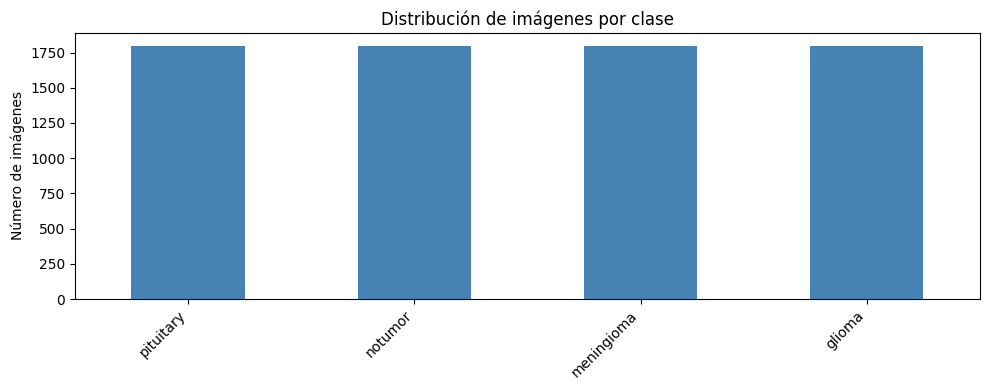

Razón entre la clase más grande y la más pequeña: 1.0x


In [5]:
conteo = df["clase"].value_counts().sort_values(ascending=False)
display(conteo.to_frame("imágenes").assign(porcentaje=(conteo / len(df) * 100).round(1)))

fig, ax = plt.subplots(figsize=(10, 4))
conteo.plot(kind="bar", ax=ax, color="steelblue")
ax.set_title("Distribución de imágenes por clase")
ax.set_ylabel("Número de imágenes")
ax.set_xlabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(f"Razón entre la clase más grande y la más pequeña: {conteo.max() / conteo.min():.1f}x")

In [6]:
# Tamaños originales de las imágenes (muestra aleatoria)
muestra = df.sample(min(400, len(df)), random_state=SEED)
tamanos = [Image.open(r).size for r in muestra["ruta"]]
anchos, altos = zip(*tamanos)

print("Ancho  ->", pd.Series(anchos).describe().round(1).to_dict())
print("Alto   ->", pd.Series(altos).describe().round(1).to_dict())
print("Tamaños más frecuentes:", pd.Series(tamanos).value_counts().head(5).to_dict())

Ancho  -> {'count': 400.0, 'mean': 462.3, 'std': 125.1, 'min': 173.0, '25%': 510.0, '50%': 512.0, '75%': 512.0, 'max': 1280.0}
Alto   -> {'count': 400.0, 'mean': 461.6, 'std': 118.7, 'min': 168.0, '25%': 512.0, '50%': 512.0, '75%': 512.0, 'max': 872.0}
Tamaños más frecuentes: {(512, 512): 282, (225, 225): 21, (300, 168): 6, (236, 236): 5, (232, 217): 4}


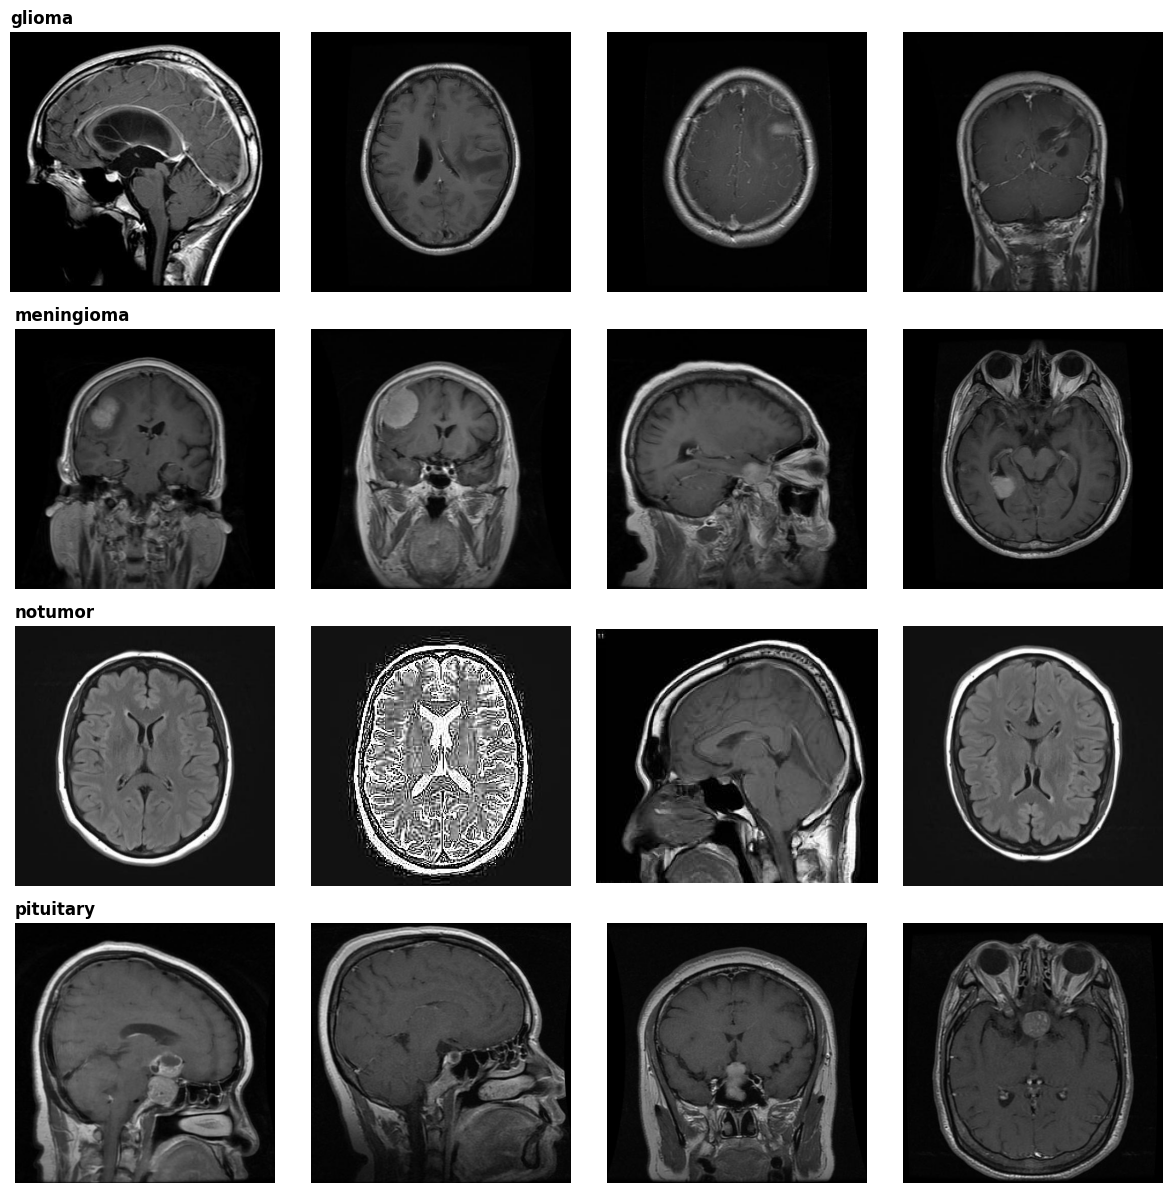

In [7]:
# Cuatro imágenes de ejemplo por clase
n_ej = 4
fig, axes = plt.subplots(NUM_CLASES, n_ej, figsize=(3 * n_ej, 3 * NUM_CLASES))
for fila, clase in enumerate(CLASES):
    rutas = df[df["clase"] == clase].sample(n_ej, random_state=SEED)["ruta"].tolist()
    for col, ruta in enumerate(rutas):
        ax = axes[fila, col]
        ax.imshow(Image.open(ruta).convert("RGB"))
        ax.axis("off")
        if col == 0:
            ax.set_title(clase, loc="left", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

**Observaciones**
- Las clases están **algo desbalanceadas**. Por eso se decidió usar separación **estratificada** y, más adelante, **pesos de clase** y métricas por clase (no solo *accuracy*).
- Las imágenes tienen **tamaños variables** y distintos recortes/orientaciones del cerebro, así que hay que reescalarlas a un tamaño fijo para poder agruparlas en lotes. Son en escala de grises; se replican a 3 canales para poder usar redes preentrenadas en ImageNet.
- Visualmente, las diferencias entre clases son sutiles (tamaño y localización de la masa, contraste), lo que anticipa dónde se concentrarán los errores (por ejemplo, entre `glioma` y `meningioma`).

### 2.5 Separación en entrenamiento, validación y prueba
Como se combinaron las particiones originales, se hace una nueva separación **estratificada** 70 % / 15 % / 15 %:
- **Entrenamiento:** ajusta los pesos de la red.
- **Validación:** sirve para comparar modelos, ajustar hiperparámetros y detener el entrenamiento.
- **Prueba:** se reserva para la evaluación final; no se usa para tomar decisiones de diseño.

In [8]:
df_train, df_tmp = train_test_split(df, test_size=0.30, stratify=df["y"], random_state=SEED)
df_val, df_test = train_test_split(df_tmp, test_size=0.50, stratify=df_tmp["y"], random_state=SEED)

for df_ in (df_train, df_val, df_test):
    df_.reset_index(drop=True, inplace=True)

print(f"Entrenamiento: {len(df_train):,}  ({len(df_train)/len(df):.0%})")
print(f"Validación:    {len(df_val):,}  ({len(df_val)/len(df):.0%})")
print(f"Prueba:        {len(df_test):,}  ({len(df_test)/len(df):.0%})")

proporciones = pd.DataFrame({
    "train": df_train["clase"].value_counts(normalize=True),
    "val":   df_val["clase"].value_counts(normalize=True),
    "test":  df_test["clase"].value_counts(normalize=True),
}).round(3)
print("\nProporción de cada clase en cada subconjunto (deben ser casi idénticas):")
display(proporciones)

Entrenamiento: 5,040  (70%)
Validación:    1,080  (15%)
Prueba:        1,080  (15%)

Proporción de cada clase en cada subconjunto (deben ser casi idénticas):


,train,val,test
clase,,,
glioma,0.25,0.25,0.25
meningioma,0.25,0.25,0.25
notumor,0.25,0.25,0.25
pituitary,0.25,0.25,0.25


### 2.6 Preprocesamiento y *pipeline* de datos
- Se leen y decodifican las imágenes con `tf.data` y se **redimensionan** a `IMG_SIZE × IMG_SIZE`.
- Los datos se entregan como valores de píxel crudos (0–255); **cada modelo incluye su propia capa de normalización** (`Rescaling`).
- Solo el conjunto de entrenamiento se baraja en cada época. `prefetch` solapa la carga de datos con el entrenamiento.
- **Pesos de clase:** se calculan con el conjunto de entrenamiento para compensar el desbalance.

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

def cargar_imagen(ruta, etiqueta):
    img = tf.io.read_file(ruta)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    return img, etiqueta

def crear_dataset(df_, entrenamiento=False):
    ds = tf.data.Dataset.from_tensor_slices((df_["ruta"].values, df_["y"].values.astype("int32")))
    if entrenamiento:
        ds = ds.shuffle(len(df_), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(cargar_imagen, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

ds_train = crear_dataset(df_train, entrenamiento=True)
ds_val = crear_dataset(df_val)
ds_test = crear_dataset(df_test)

pesos = compute_class_weight("balanced", classes=np.arange(NUM_CLASES), y=df_train["y"].values)
class_weight = {i: float(w) for i, w in enumerate(pesos)}
print("Pesos de clase:")
for i, c in enumerate(CLASES):
    print(f"  {c:12s} {class_weight[i]:.2f}")

imgs, labs = next(iter(ds_train))
print("\nLote de ejemplo:", imgs.shape, imgs.dtype, "| etiquetas:", labs.shape)
print("Rango de píxeles:", float(tf.reduce_min(imgs)), "-", float(tf.reduce_max(imgs)))

Pesos de clase:
  glioma       1.00
  meningioma   1.00
  notumor      1.00
  pituitary    1.00

Lote de ejemplo: (32, 160, 160, 3) <dtype: 'float32'> | etiquetas: (32,)
Rango de píxeles: 0.0 - 255.0


## 3. Desarrollo del modelo

### 3.1 Funciones auxiliares
Se definen funciones reutilizables para compilar, graficar curvas de aprendizaje y evaluar (reporte por clase y matriz de confusión).

In [10]:
os.makedirs("modelos", exist_ok=True)

def compilar(modelo, lr=1e-3):
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                   loss="sparse_categorical_crossentropy",
                   metrics=["accuracy"])
    return modelo

def unir_historias(*historias):
    unido = {}
    for h in historias:
        d = h.history if hasattr(h, "history") else h
        for k, v in d.items():
            unido.setdefault(k, []).extend(v)
    return unido

def graficar_historia(hist, titulo):
    h = hist.history if hasattr(hist, "history") else hist
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h["loss"], label="entrenamiento")
    ax[0].plot(h["val_loss"], label="validación")
    ax[0].set_title(f"{titulo} – pérdida"); ax[0].set_xlabel("época"); ax[0].legend()
    ax[1].plot(h["accuracy"], label="entrenamiento")
    ax[1].plot(h["val_accuracy"], label="validación")
    ax[1].set_title(f"{titulo} – accuracy"); ax[1].set_xlabel("época"); ax[1].legend()
    plt.tight_layout()
    plt.show()

def predecir_dataset(modelo, ds):
    probs = modelo.predict(ds, verbose=0)
    return probs.argmax(axis=1), probs

def evaluar(modelo, ds, y_true, nombre, reporte=True):
    loss, acc = modelo.evaluate(ds, verbose=0)
    y_pred, _ = predecir_dataset(modelo, ds)
    print(f"[{nombre}] pérdida = {loss:.4f} | accuracy = {acc:.4f}")
    if reporte:
        print(classification_report(y_true, y_pred, target_names=CLASES, digits=3, zero_division=0))
    return {"loss": loss, "acc": acc, "y_pred": y_pred}

def graficar_confusion(y_true, y_pred, titulo):
    cm = confusion_matrix(y_true, y_pred, normalize="true")
    fig, ax = plt.subplots(figsize=(8, 8))
    ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(ax=ax, cmap="Blues",
                                                           xticks_rotation=45, colorbar=False,
                                                           values_format=".2f")
    ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

y_val = df_val["y"].values
y_test = df_test["y"].values

### 3.2 Arquitectura del modelo base (CNN sencilla)

Se parte de una red convolucional pequeña, sin técnicas de regularización, para tener una **línea base**:

| Bloque | Capas | Función |
|---|---|---|
| Normalización | `Rescaling(1/255)` | Lleva los píxeles de [0, 255] a [0, 1] |
| Extracción de características | 3 × (`Conv2D` + `MaxPooling2D`) con 32, 64 y 128 filtros | Las convoluciones detectan patrones locales (bordes → texturas → partes de objetos); el *pooling* reduce la resolución y da cierta invarianza a pequeños desplazamientos |
| Clasificación | `Flatten` → `Dense(128)` → `Dense(12, softmax)` | Combina las características y produce una probabilidad por clase |

Se entrena con **Adam** (lr = 1e-3) y entropía cruzada categórica dispersa (las etiquetas son enteros).

In [11]:
def crear_modelo_v1():
    return keras.Sequential([
        keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        layers.Rescaling(1.0 / 255),
        layers.Conv2D(32, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(64, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Conv2D(128, 3, padding="same", activation="relu"),
        layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(NUM_CLASES, activation="softmax"),
    ], name="cnn_base")

modelo_v1 = compilar(crear_modelo_v1(), lr=1e-3)
modelo_v1.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,647,492 (25.36 MB)

 Trainable params: 6,647,492 (25.36 MB)

 Non-trainable params: 0 (0.00 B)

### 3.3 Entrenamiento del modelo base
Se guarda el mejor modelo según la *accuracy* de validación (`ModelCheckpoint`). No se usa ninguna técnica anti-sobreajuste todavía, a propósito.

In [12]:
ckpt_v1 = keras.callbacks.ModelCheckpoint("modelos/v1_base.keras", monitor="val_accuracy",
                                          save_best_only=True, verbose=0)
t0 = time.time()
hist_v1 = modelo_v1.fit(ds_train, validation_data=ds_val, epochs=EPOCHS_V1,
                        callbacks=[ckpt_v1], verbose=2)
t_v1 = time.time() - t0
print(f"\nTiempo de entrenamiento: {t_v1/60:.1f} min")
modelo_v1 = keras.models.load_model("modelos/v1_base.keras")   # mejor época según validación

Epoch 1/15
158/158 - 42s - 264ms/step - accuracy: 0.6849 - loss: 0.7581 - val_accuracy: 0.7750 - val_loss: 0.5901
Epoch 2/15
158/158 - 9s - 59ms/step - accuracy: 0.8488 - loss: 0.4080 - val_accuracy: 0.8426 - val_loss: 0.4144
Epoch 3/15
158/158 - 9s - 58ms/step - accuracy: 0.9139 - loss: 0.2383 - val_accuracy: 0.8676 - val_loss: 0.3904
Epoch 4/15
158/158 - 9s - 59ms/step - accuracy: 0.9530 - loss: 0.1418 - val_accuracy: 0.9000 - val_loss: 0.3094
Epoch 5/15
158/158 - 10s - 66ms/step - accuracy: 0.9736 - loss: 0.0758 - val_accuracy: 0.9176 - val_loss: 0.3310
Epoch 6/15
158/158 - 10s - 64ms/step - accuracy: 0.9798 - loss: 0.0622 - val_accuracy: 0.8963 - val_loss: 0.4270
Epoch 7/15
158/158 - 9s - 57ms/step - accuracy: 0.9907 - loss: 0.0308 - val_accuracy: 0.9213 - val_loss: 0.3969
Epoch 8/15
158/158 - 8s - 51ms/step - accuracy: 0.9925 - loss: 0.0305 - val_accuracy: 0.9259 - val_loss: 0.3696
Epoch 9/15
158/158 - 11s - 67ms/step - accuracy: 0.9919 - loss: 0.0296 - val_accuracy: 0.9269 - val_

### 3.4 Evaluación del modelo base (entrenamiento vs. validación)

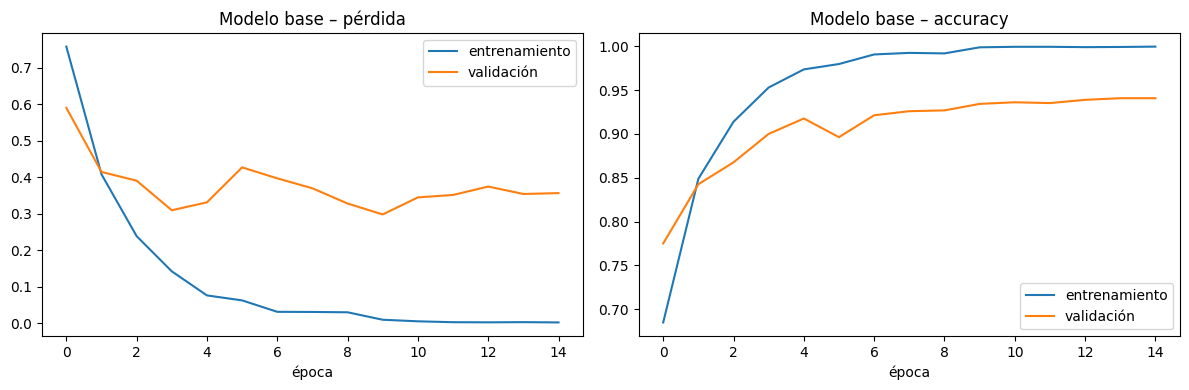

In [13]:
graficar_historia(hist_v1, "Modelo base")

[Base – validación] pérdida = 0.3540 | accuracy = 0.9407
              precision    recall  f1-score   support

      glioma      0.960     0.889     0.923       270
  meningioma      0.890     0.926     0.907       270
     notumor      0.952     0.956     0.954       270
   pituitary      0.964     0.993     0.978       270

    accuracy                          0.941      1080
   macro avg      0.941     0.941     0.941      1080
weighted avg      0.941     0.941     0.941      1080



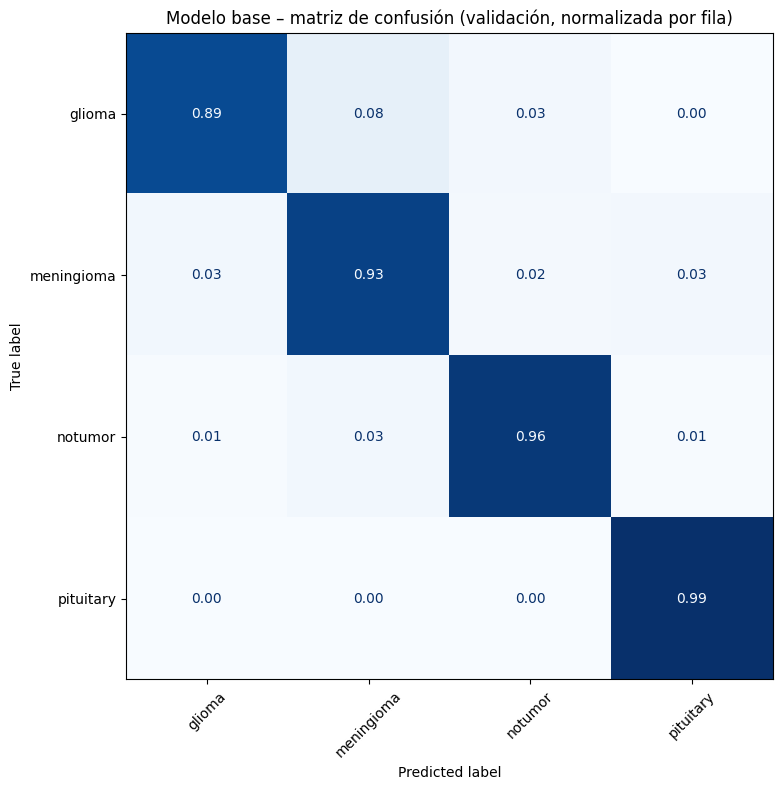

In [14]:
res_v1_val = evaluar(modelo_v1, ds_val, y_val, "Base – validación")
graficar_confusion(y_val, res_v1_val["y_pred"], "Modelo base – matriz de confusión (validación, normalizada por fila)")

In [15]:
mejor_ep = int(np.argmax(hist_v1.history["val_accuracy"])) + 1
print(f"Mejor época (validación): {mejor_ep}")
print(f"accuracy de entrenamiento en la última época: {hist_v1.history['accuracy'][-1]:.4f}")
print(f"accuracy de validación en la última época:    {hist_v1.history['val_accuracy'][-1]:.4f}")
print(f"Brecha (entrenamiento - validación): {hist_v1.history['accuracy'][-1] - hist_v1.history['val_accuracy'][-1]:.4f}")

Mejor época (validación): 14
accuracy de entrenamiento en la última época: 0.9996
accuracy de validación en la última época:    0.9407
Brecha (entrenamiento - validación): 0.0589


**Diagnóstico del modelo base.** Una red sin regularización suele aprender muy rápido el conjunto de entrenamiento mientras la pérdida de validación deja de mejorar (o empeora): **sobreajuste**. La brecha entre las curvas de entrenamiento y validación y la matriz de confusión (qué clases se confunden) guían las mejoras de la siguiente sección:
- Si hay sobreajuste → aumento de datos, *Dropout*, regularización L2, detención temprana.
- Si el entrenamiento es inestable o lento → normalización por lotes y ajuste de la tasa de aprendizaje.
- Si las clases pequeñas tienen bajo *recall* → pesos de clase.
- Si la capacidad de las características aprendidas desde cero es limitada → transferencia de aprendizaje.

## 4. Ajuste del modelo

Se hacen dos iteraciones de mejora sobre el modelo base.

### 4.1 Iteración 1: CNN regularizada (arquitectura + técnicas de regularización)

Cambios respecto al modelo base y la razón de cada uno:

| Cambio | Por qué debería ayudar |
|---|---|
| **Aumento de datos** (`RandomFlip`, `RandomRotation`, `RandomZoom`, `RandomContrast`) | Genera variaciones nuevas de cada imagen en cada época; la red ve "más datos" distintos y no puede memorizar los píxeles exactos. Solo actúa en entrenamiento. |
| **Dos convoluciones por bloque** y un bloque más (32→256 filtros) | Mayor profundidad y campo receptivo para aprender características más ricas. |
| **`BatchNormalization`** | Estabiliza y acelera el entrenamiento permitiendo tasas de aprendizaje más altas; además aporta algo de regularización. |
| **`GlobalAveragePooling2D`** en lugar de `Flatten` | Reduce drásticamente los parámetros de la capa densa (menos sobreajuste) y hace la red independiente del tamaño de la imagen. |
| **`Dropout`** | Apaga neuronas al azar en entrenamiento, evitando co-adaptaciones. |
| **Regularización L2** en convoluciones y capa densa | Penaliza pesos grandes → modelos más suaves. |
| **Pesos de clase** | Penaliza más los errores en clases con pocos ejemplos, mejorando su *recall*. |
| **`EarlyStopping` + `ReduceLROnPlateau`** | Detiene el entrenamiento cuando la validación deja de mejorar y reduce el *learning rate* en mesetas para afinar la convergencia. |

In [16]:
aumento = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.10),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="aumento_datos")

def crear_modelo_v2(dropout=0.4, l2=1e-4):
    reg = regularizers.l2(l2)
    entrada = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = aumento(entrada)
    x = layers.Rescaling(1.0 / 255)(x)
    for filtros in (32, 64, 128, 256):
        for _ in range(2):
            x = layers.Conv2D(filtros, 3, padding="same", use_bias=False, kernel_regularizer=reg)(x)
            x = layers.BatchNormalization()(x)
            x = layers.Activation("relu")(x)
        x = layers.MaxPooling2D()(x)
        x = layers.Dropout(0.1)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=reg)(x)
    x = layers.Dropout(dropout)(x)
    salida = layers.Dense(NUM_CLASES, activation="softmax")(x)
    return keras.Model(entrada, salida, name="cnn_regularizada")

crear_modelo_v2().summary()

Model: "cnn_regularizada"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_datos (Sequential)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 160, 160, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 160, 160, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 160, 160, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 80, 80, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 80, 80, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 40, 40, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,208,548 (4.61 MB)

 Trainable params: 1,206,628 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

#### Ajuste de hiperparámetros: tasa de aprendizaje
La tasa de aprendizaje es el hiperparámetro con mayor impacto. Se prueban tres valores con entrenamientos cortos (`EPOCHS_BUSQUEDA` épocas) y se elige el de mayor *accuracy* de validación.

lr = 0.01     -> mejor val_accuracy = 0.5139
lr = 0.001    -> mejor val_accuracy = 0.7065
lr = 0.0003   -> mejor val_accuracy = 0.6556

Mejor learning rate: 0.001


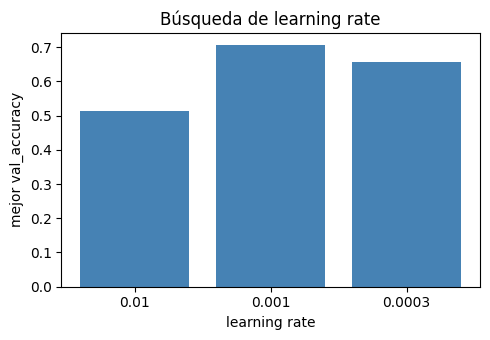

In [17]:
resultados_lr = {}
for lr in [1e-2, 1e-3, 3e-4]:
    keras.utils.set_random_seed(SEED)
    m = compilar(crear_modelo_v2(), lr=lr)
    h = m.fit(ds_train, validation_data=ds_val, epochs=EPOCHS_BUSQUEDA,
              class_weight=class_weight, verbose=0)
    resultados_lr[lr] = max(h.history["val_accuracy"])
    print(f"lr = {lr:<8g} -> mejor val_accuracy = {resultados_lr[lr]:.4f}")

mejor_lr = max(resultados_lr, key=resultados_lr.get)
print(f"\nMejor learning rate: {mejor_lr:g}")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar([f"{k:g}" for k in resultados_lr], list(resultados_lr.values()), color="steelblue")
ax.set_xlabel("learning rate"); ax.set_ylabel("mejor val_accuracy"); ax.set_title("Búsqueda de learning rate")
plt.tight_layout(); plt.show()

#### Entrenamiento del modelo regularizado

In [18]:
keras.utils.set_random_seed(SEED)
modelo_v2 = compilar(crear_modelo_v2(), lr=mejor_lr)

callbacks_v2 = [
    keras.callbacks.ModelCheckpoint("modelos/v2_regularizado.keras", monitor="val_accuracy",
                                    save_best_only=True, verbose=0),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1),
]

t0 = time.time()
hist_v2 = modelo_v2.fit(ds_train, validation_data=ds_val, epochs=EPOCHS_V2,
                        class_weight=class_weight, callbacks=callbacks_v2, verbose=2)
t_v2 = time.time() - t0
print(f"\nTiempo de entrenamiento: {t_v2/60:.1f} min")
modelo_v2 = keras.models.load_model("modelos/v2_regularizado.keras")

Epoch 1/40
158/158 - 32s - 205ms/step - accuracy: 0.5950 - loss: 1.0831 - val_accuracy: 0.2556 - val_loss: 2.9165 - learning_rate: 0.0010
Epoch 2/40
158/158 - 26s - 167ms/step - accuracy: 0.6845 - loss: 0.8860 - val_accuracy: 0.3352 - val_loss: 1.9925 - learning_rate: 0.0010
Epoch 3/40
158/158 - 26s - 167ms/step - accuracy: 0.7252 - loss: 0.8131 - val_accuracy: 0.5935 - val_loss: 1.3405 - learning_rate: 0.0010
Epoch 4/40
158/158 - 26s - 165ms/step - accuracy: 0.7484 - loss: 0.7542 - val_accuracy: 0.5074 - val_loss: 1.8175 - learning_rate: 0.0010
Epoch 5/40
158/158 - 26s - 165ms/step - accuracy: 0.7764 - loss: 0.6941 - val_accuracy: 0.5556 - val_loss: 1.4422 - learning_rate: 0.0010
Epoch 6/40

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
158/158 - 41s - 259ms/step - accuracy: 0.7861 - loss: 0.6701 - val_accuracy: 0.4583 - val_loss: 2.5025 - learning_rate: 0.0010
Epoch 7/40
158/158 - 27s - 168ms/step - accuracy: 0.8147 - loss: 0.5908 - val_accuracy: 0.6676 

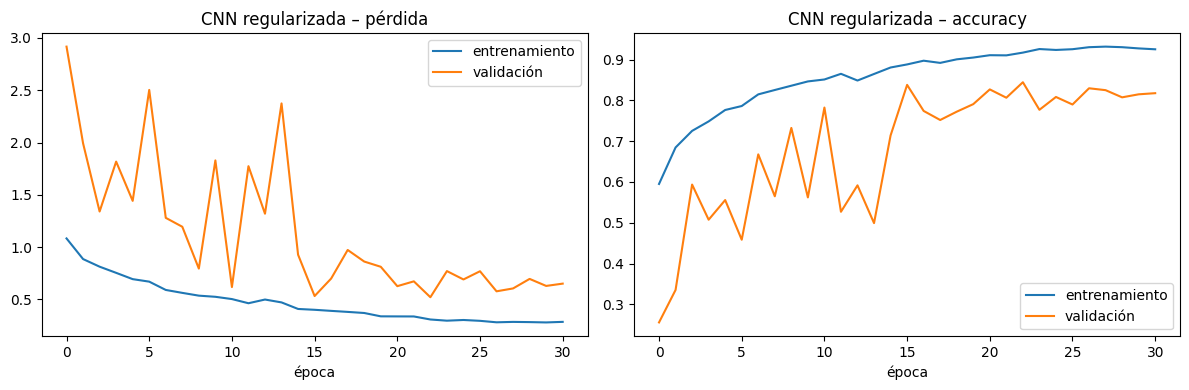

[Regularizada – validación] pérdida = 0.5211 | accuracy = 0.8444
              precision    recall  f1-score   support

      glioma      0.950     0.844     0.894       270
  meningioma      0.939     0.574     0.713       270
     notumor      0.907     0.978     0.941       270
   pituitary      0.690     0.981     0.810       270

    accuracy                          0.844      1080
   macro avg      0.872     0.844     0.840      1080
weighted avg      0.872     0.844     0.840      1080



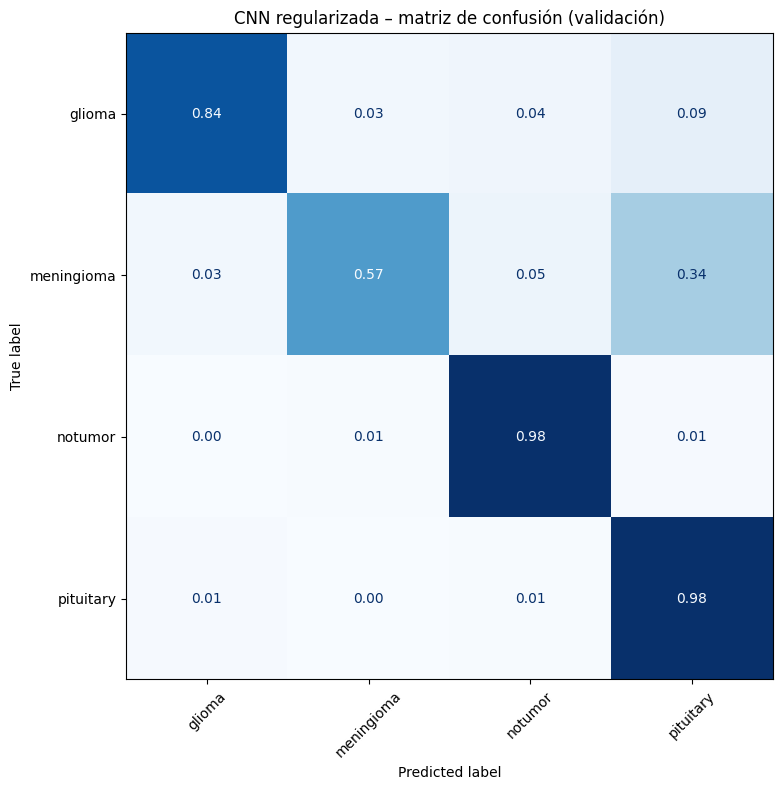

In [19]:
graficar_historia(hist_v2, "CNN regularizada")
res_v2_val = evaluar(modelo_v2, ds_val, y_val, "Regularizada – validación")
graficar_confusion(y_val, res_v2_val["y_pred"], "CNN regularizada – matriz de confusión (validación)")

### 4.2 Iteración 2: transferencia de aprendizaje con MobileNetV2

Entrenar desde cero con ~10 mil imágenes limita la calidad de las características. **MobileNetV2** ya fue entrenada en ImageNet (más de un millón de imágenes), por lo que sus capas convolucionales ya detectan bordes, texturas y formas útiles. Es además una red ligera (convoluciones separables en profundidad y bloques residuales invertidos), adecuada para aplicaciones embebidas como un clasificador en un robot o contenedor inteligente.

Se entrena en **dos fases**:
1. **Extracción de características:** la base se congela y solo se entrena la cabeza nueva (`GlobalAveragePooling2D` → `Dropout` → `Dense softmax`) con *learning rate* alto.
2. **Fine-tuning:** se descongelan las últimas capas de la base y se continúa con un *learning rate* muy pequeño (1e-5) para adaptar las características de alto nivel al problema sin destruir lo aprendido. Las capas `BatchNormalization` permanecen congeladas.

In [20]:
def crear_modelo_v3(dropout=0.3):
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False,
                                          weights="imagenet" if USE_PRETRAINED else None)
    base.trainable = False
    entrada = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
    x = aumento(entrada)
    x = layers.Rescaling(scale=1.0 / 127.5, offset=-1.0)(x)   # MobileNetV2 espera entradas en [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    salida = layers.Dense(NUM_CLASES, activation="softmax")(x)
    return keras.Model(entrada, salida, name="mobilenetv2_transfer"), base

modelo_v3, base_v3 = crear_modelo_v3()
compilar(modelo_v3, lr=1e-3)
modelo_v3.summary()
print("Parámetros entrenables (fase 1):", sum(int(np.prod(w.shape)) for w in modelo_v3.trainable_weights))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_8 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento_datos (Sequential)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_6 (Rescaling)         │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_5      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Parámetros entrenables (fase 1): 5124


In [21]:
#  Fase 1: entrenar solo la cabeza
ckpt_v3 = keras.callbacks.ModelCheckpoint("modelos/v3_mobilenet.keras", monitor="val_accuracy",
                                          save_best_only=True, verbose=0)
t0 = time.time()
hist_v3a = modelo_v3.fit(ds_train, validation_data=ds_val, epochs=EPOCHS_V3_HEAD,
                         class_weight=class_weight, callbacks=[ckpt_v3], verbose=2)
print(f"\nFase 1 terminada en {(time.time()-t0)/60:.1f} min")

Epoch 1/10
158/158 - 19s - 117ms/step - accuracy: 0.7028 - loss: 0.7656 - val_accuracy: 0.7185 - val_loss: 0.7623
Epoch 2/10
158/158 - 10s - 63ms/step - accuracy: 0.8194 - loss: 0.4995 - val_accuracy: 0.7269 - val_loss: 0.7389
Epoch 3/10
158/158 - 11s - 69ms/step - accuracy: 0.8419 - loss: 0.4415 - val_accuracy: 0.7630 - val_loss: 0.6317
Epoch 4/10
158/158 - 10s - 63ms/step - accuracy: 0.8484 - loss: 0.4111 - val_accuracy: 0.7806 - val_loss: 0.5715
Epoch 5/10
158/158 - 8s - 53ms/step - accuracy: 0.8577 - loss: 0.3909 - val_accuracy: 0.7630 - val_loss: 0.6369
Epoch 6/10
158/158 - 11s - 67ms/step - accuracy: 0.8579 - loss: 0.3841 - val_accuracy: 0.7602 - val_loss: 0.6501
Epoch 7/10
158/158 - 10s - 60ms/step - accuracy: 0.8585 - loss: 0.3769 - val_accuracy: 0.7722 - val_loss: 0.6131
Epoch 8/10
158/158 - 10s - 63ms/step - accuracy: 0.8708 - loss: 0.3551 - val_accuracy: 0.7861 - val_loss: 0.6119
Epoch 9/10
158/158 - 8s - 53ms/step - accuracy: 0.8698 - loss: 0.3547 - val_accuracy: 0.7509 - v

In [22]:
# fine-tuning de las últimas capas
base_v3.trainable = True
for capa in base_v3.layers[:-40]:
    capa.trainable = False
for capa in base_v3.layers:
    if isinstance(capa, layers.BatchNormalization):
        capa.trainable = False

compilar(modelo_v3, lr=1e-5)
print("Parámetros entrenables (fase 2):", sum(int(np.prod(w.shape)) for w in modelo_v3.trainable_weights))

t0 = time.time()
hist_v3b = modelo_v3.fit(ds_train, validation_data=ds_val, epochs=EPOCHS_V3_FT,
                         class_weight=class_weight, callbacks=[ckpt_v3], verbose=2)
t_v3 = time.time() - t0
print(f"\nFase 2 terminada en {t_v3/60:.1f} min")
modelo_v3 = keras.models.load_model("modelos/v3_mobilenet.keras")

Parámetros entrenables (fase 2): 1668484
Epoch 1/10
158/158 - 18s - 117ms/step - accuracy: 0.8748 - loss: 0.3414 - val_accuracy: 0.7648 - val_loss: 0.6762
Epoch 2/10
158/158 - 18s - 116ms/step - accuracy: 0.8927 - loss: 0.2984 - val_accuracy: 0.7898 - val_loss: 0.5951
Epoch 3/10
158/158 - 10s - 65ms/step - accuracy: 0.9044 - loss: 0.2589 - val_accuracy: 0.7954 - val_loss: 0.5952
Epoch 4/10
158/158 - 10s - 65ms/step - accuracy: 0.9020 - loss: 0.2605 - val_accuracy: 0.8037 - val_loss: 0.5536
Epoch 5/10
158/158 - 9s - 58ms/step - accuracy: 0.9111 - loss: 0.2406 - val_accuracy: 0.8167 - val_loss: 0.5045
Epoch 6/10
158/158 - 11s - 73ms/step - accuracy: 0.9173 - loss: 0.2268 - val_accuracy: 0.8417 - val_loss: 0.4624
Epoch 7/10
158/158 - 10s - 63ms/step - accuracy: 0.9232 - loss: 0.2086 - val_accuracy: 0.8037 - val_loss: 0.5669
Epoch 8/10
158/158 - 10s - 63ms/step - accuracy: 0.9270 - loss: 0.1979 - val_accuracy: 0.8250 - val_loss: 0.5544
Epoch 9/10
158/158 - 9s - 59ms/step - accuracy: 0.9308

In [ ]:
hist_v3 = unir_historias(hist_v3a, hist_v3b)
graficar_historia(hist_v3, "MobileNetV2 (fase 1 + fine-tuning)")
res_v3_val = evaluar(modelo_v3, ds_val, y_val, "MobileNetV2 – validación")
graficar_confusion(y_val, res_v3_val["y_pred"], "MobileNetV2 – matriz de confusión (validación)")

### 4.3 Comparación en validación y selección del modelo final
La selección se hace **únicamente con el conjunto de validación**, para que el conjunto de prueba siga siendo una estimación imparcial.

In [24]:
modelos = {"v1 – CNN base": modelo_v1, "v2 – CNN regularizada": modelo_v2, "v3 – MobileNetV2": modelo_v3}
val_res = {"v1 – CNN base": res_v1_val, "v2 – CNN regularizada": res_v2_val, "v3 – MobileNetV2": res_v3_val}

tabla_val = pd.DataFrame({
    "Parámetros": {k: m.count_params() for k, m in modelos.items()},
    "Val loss": {k: r["loss"] for k, r in val_res.items()},
    "Val accuracy": {k: r["acc"] for k, r in val_res.items()},
}).round(4)
display(tabla_val)

nombre_final = tabla_val["Val accuracy"].idxmax()
modelo_final = modelos[nombre_final]
modelo_final.save("modelo_final.keras")
print(f"\nModelo seleccionado (mayor accuracy de validación): {nombre_final}")
print("Guardado en: modelo_final.keras")

,Parámetros,Val loss,Val accuracy
v1 – CNN base,6647492,0.3540,0.9407
v2 – CNN regularizada,1208548,0.5211,0.8444
v3 – MobileNetV2,2263108,0.4624,0.8417



Modelo seleccionado (mayor accuracy de validación): v1 – CNN base
Guardado en: modelo_final.keras


### 4.4 ¿Qué cambios funcionaron y por qué?

La tabla anterior y las curvas permiten atribuir cada mejora a una técnica concreta:

1. **Aumento de datos + Dropout + L2 + BatchNorm (v1 → v2).** La señal de que funcionan es que la brecha entre entrenamiento y validación se reduce y la pérdida de validación se mantiene cerca de la de entrenamiento durante más épocas. Funciona porque el aumento de datos amplía artificialmente la variedad de ejemplos y Dropout/L2 limitan la capacidad efectiva de memorización, de modo que la red debe aprender características que **generalizan** (forma y textura del material) y no detalles específicos de cada foto. `BatchNormalization` permitió usar una tasa de aprendizaje más alta con un entrenamiento estable.
2. **Pesos de clase.** Mejoran el *recall* de las clases minoritarias (revisar el reporte por clase de cada modelo): sin ellos, minimizar el error global favorece a las clases con más ejemplos.
3. **Búsqueda de *learning rate*, `ReduceLROnPlateau` y `EarlyStopping`.** Un *learning rate* demasiado alto vuelve inestable el entrenamiento y uno demasiado bajo lo vuelve lento; reducirlo en las mesetas permite un ajuste fino de los pesos, y detener a tiempo evita sobreentrenar.
4. **Transferencia de aprendizaje (v2 → v3).** Las características visuales generales aprendidas en ImageNet (bordes, texturas, formas) se reutilizan, por lo que la red necesita menos datos y épocas para separar las clases (aunque ImageNet son fotos naturales y no MRI, esas características de bajo nivel siguen siendo útiles). El *fine-tuning* con *learning rate* muy bajo adapta las capas superiores al dominio de las resonancias magnéticas sin borrar el conocimiento previo.

Para comprobar con números qué cambió entre iteraciones, se imprime a continuación el cambio de cada paso.

In [25]:
v1, v2, v3 = (val_res[k]["acc"] for k in ["v1 – CNN base", "v2 – CNN regularizada", "v3 – MobileNetV2"])
print(f"v1 -> v2 (regularización + arquitectura): {100*(v2 - v1):+.2f} puntos porcentuales de val accuracy")
print(f"v2 -> v3 (transferencia de aprendizaje):  {100*(v3 - v2):+.2f} puntos porcentuales de val accuracy")

brecha = {
    "v1": hist_v1.history["accuracy"][-1] - hist_v1.history["val_accuracy"][-1],
    "v2": hist_v2.history["accuracy"][-1] - hist_v2.history["val_accuracy"][-1],
    "v3": hist_v3["accuracy"][-1] - hist_v3["val_accuracy"][-1],
}
print("\nBrecha final entrenamiento - validación (accuracy):")
for k, v in brecha.items():
    print(f"  {k}: {v:+.4f}")
print("(en v2/v3 el aumento de datos hace que la accuracy de entrenamiento se mida con imágenes distorsionadas)")

v1 -> v2 (regularización + arquitectura): -9.63 puntos porcentuales de val accuracy
v2 -> v3 (transferencia de aprendizaje):  -0.28 puntos porcentuales de val accuracy

Brecha final entrenamiento - validación (accuracy):
  v1: +0.0589
  v2: +0.1076
  v3: +0.1051
(en v2/v3 el aumento de datos hace que la accuracy de entrenamiento se mida con imágenes distorsionadas)


## 5. Resultados

Ahora sí se usa el **conjunto de prueba**, que no intervino en el entrenamiento ni en la selección de modelos. Primero se muestran los tres modelos para completar la comparación y después el análisis detallado del modelo final.

[v1 – CNN base] pérdida = 0.4429 | accuracy = 0.9343
[v2 – CNN regularizada] pérdida = 0.4825 | accuracy = 0.8435
[v3 – MobileNetV2] pérdida = 0.4325 | accuracy = 0.8463


,Parámetros,Val accuracy,Test accuracy,Test loss
v1 – CNN base,6647492,0.9407,0.9343,0.4429
v2 – CNN regularizada,1208548,0.8444,0.8435,0.4825
v3 – MobileNetV2,2263108,0.8417,0.8463,0.4325


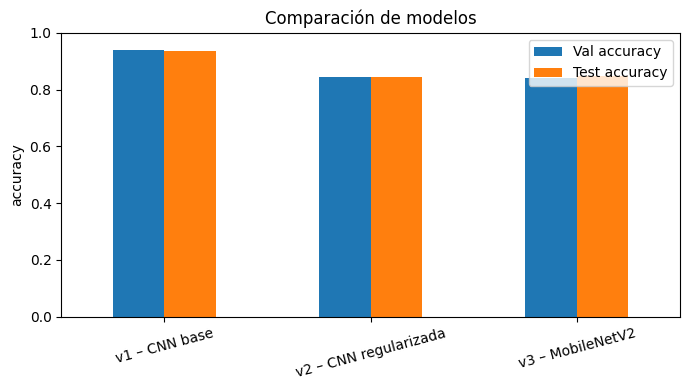

In [26]:
test_res = {k: evaluar(m, ds_test, y_test, k, reporte=False) for k, m in modelos.items()}

tabla_final = pd.DataFrame({
    "Parámetros": {k: m.count_params() for k, m in modelos.items()},
    "Val accuracy": {k: val_res[k]["acc"] for k in modelos},
    "Test accuracy": {k: test_res[k]["acc"] for k in modelos},
    "Test loss": {k: test_res[k]["loss"] for k in modelos},
}).round(4)
display(tabla_final)

fig, ax = plt.subplots(figsize=(7, 4))
tabla_final[["Val accuracy", "Test accuracy"]].plot(kind="bar", ax=ax)
ax.set_ylabel("accuracy"); ax.set_title("Comparación de modelos"); ax.set_ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

### 5.1 Modelo final: evaluación detallada en prueba

In [27]:
print("Modelo final:", nombre_final)
res_final = test_res[nombre_final]
print(classification_report(y_test, res_final["y_pred"], target_names=CLASES, digits=3, zero_division=0))

Modelo final: v1 – CNN base
              precision    recall  f1-score   support

      glioma      0.941     0.885     0.912       270
  meningioma      0.883     0.896     0.890       270
     notumor      0.956     0.967     0.961       270
   pituitary      0.957     0.989     0.973       270

    accuracy                          0.934      1080
   macro avg      0.934     0.934     0.934      1080
weighted avg      0.934     0.934     0.934      1080



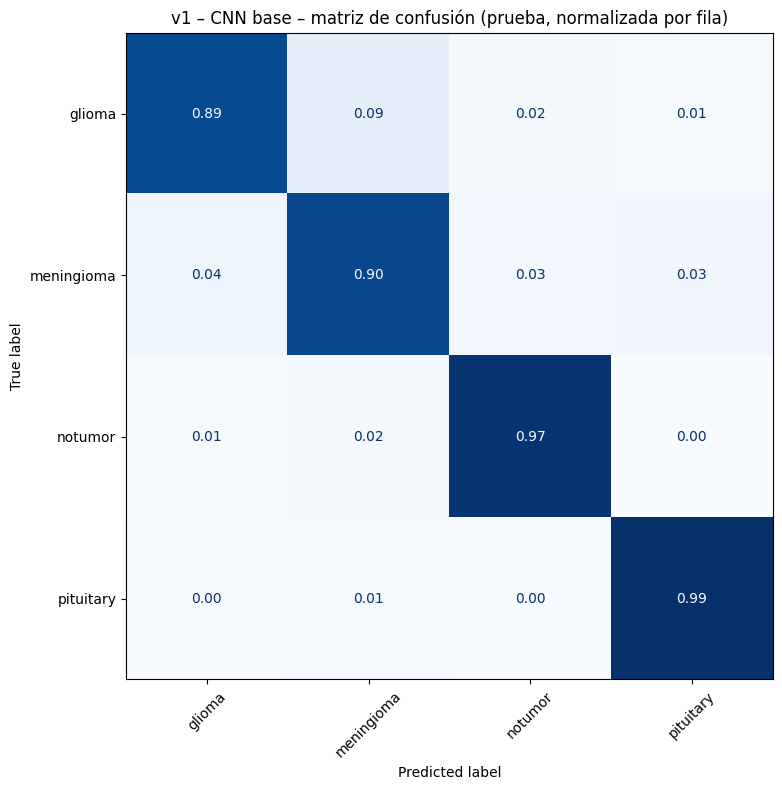

In [28]:
graficar_confusion(y_test, res_final["y_pred"], f"{nombre_final} – matriz de confusión (prueba, normalizada por fila)")

In [29]:
# Pares de clases más confundidos
cm = confusion_matrix(y_test, res_final["y_pred"])
errores = [(CLASES[i], CLASES[j], int(cm[i, j])) for i in range(NUM_CLASES) for j in range(NUM_CLASES)
           if i != j and cm[i, j] > 0]
errores = sorted(errores, key=lambda t: -t[2])[:6]
print("Confusiones más frecuentes (real -> predicha : cantidad)")
for real, pred, n in errores:
    print(f"  {real:12s} -> {pred:12s} : {n}")

Confusiones más frecuentes (real -> predicha : cantidad)
  glioma       -> meningioma   : 23
  meningioma   -> glioma       : 12
  meningioma   -> pituitary    : 9
  meningioma   -> notumor      : 7
  notumor      -> meningioma   : 6
  glioma       -> notumor      : 5


Errores en prueba: 71 de 1080 (6.6%)


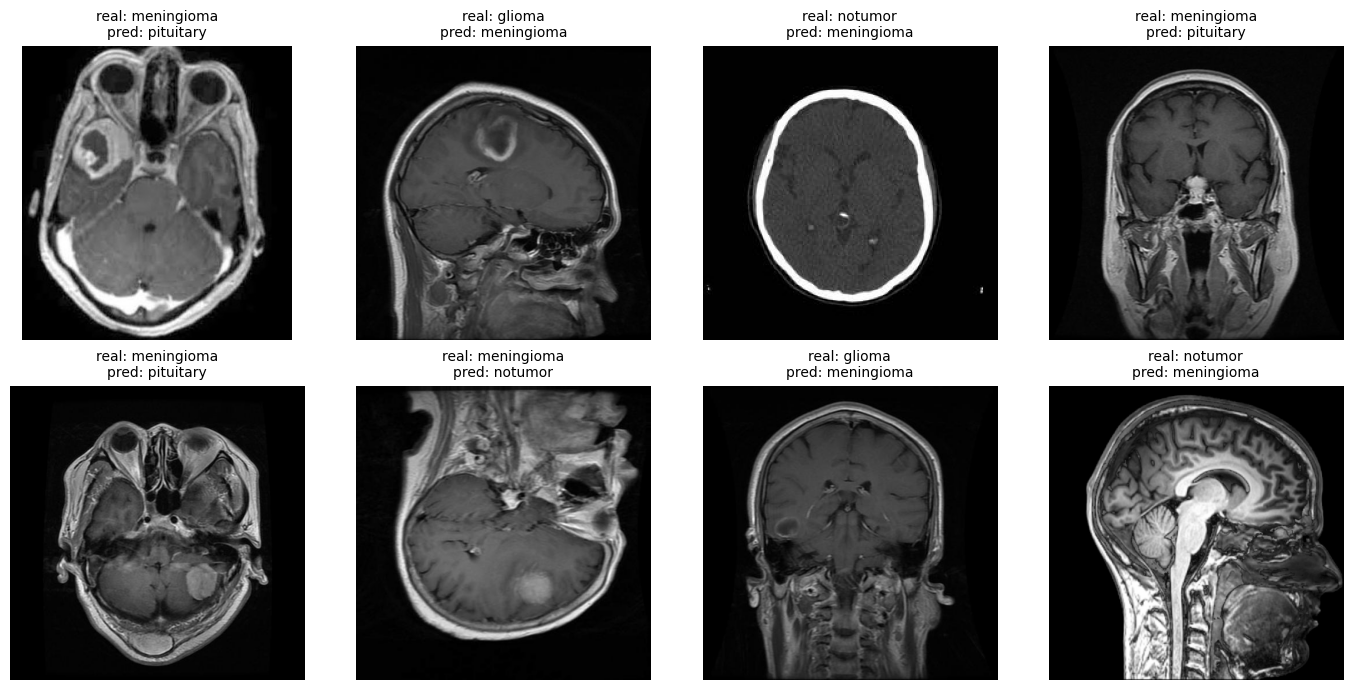

In [30]:
# Ejemplos de imágenes mal clasificadas
idx_err = np.where(res_final["y_pred"] != y_test)[0]
print(f"Errores en prueba: {len(idx_err)} de {len(y_test)} ({len(idx_err)/len(y_test):.1%})")

rng = np.random.default_rng(SEED)
elegidos = rng.choice(idx_err, size=min(8, len(idx_err)), replace=False) if len(idx_err) else []
if len(elegidos):
    fig, axes = plt.subplots(2, 4, figsize=(14, 7))
    for ax, i in zip(axes.ravel(), elegidos):
        ax.imshow(Image.open(df_test["ruta"][i]).convert("RGB"))
        ax.set_title(f"real: {CLASES[y_test[i]]}\npred: {CLASES[res_final['y_pred'][i]]}", fontsize=10)
        ax.axis("off")
    plt.tight_layout(); plt.show()

## 6. Conclusiones

**Sobre el desarrollo.** Se resolvió un problema de clasificación de resonancias magnéticas cerebrales en 4 clases (`glioma`, `meningioma`, `pituitary`, `notumor`) con redes convolucionales en Keras/TensorFlow, siguiendo un proceso iterativo: línea base → regularización y ajuste de hiperparámetros → transferencia de aprendizaje. Las cifras exactas (accuracy, precisión y *recall* por clase) están en la tabla comparativa y en el reporte de clasificación de la sección 5; la separación estratificada y la selección del modelo con validación garantizan que la métrica de prueba sea una estimación honesta del desempeño con datos que el modelo no vio.

**Sobre lo que mejoró el modelo.** Las técnicas que atacan el sobreajuste (aumento de datos, Dropout, L2, BatchNorm, detención temprana) y el aprovechamiento de características preentrenadas son las que más inciden en generalizar mejor que una CNN sencilla; las curvas de aprendizaje y la brecha entrenamiento–validación (sección 4.4) permiten verificarlo en cada iteración.

**Limitaciones**
- Las imágenes se reducen a 160 × 160 píxeles por costo computacional; se pierde detalle fino que podría ser relevante para tumores pequeños.
- Se clasifican **cortes 2D individuales**, no estudios completos en 3D: cortes del mismo paciente pueden aparecer en entrenamiento y prueba a la vez, lo que puede inflar las métricas (*fuga de datos* por paciente). El dataset no trae identificador de paciente, así que no se pudo separar por paciente.
- El dataset puede contener imágenes duplicadas o con etiquetas dudosas, lo que impone un techo a la métrica alcanzable.
- Los datos provienen de pocas fuentes y equipos; un modelo así puede degradarse con escáneres, protocolos o poblaciones distintos.
- Una sola partición y una sola semilla: no se midió la variabilidad entre ejecuciones.

**Posibles mejoras**
1. Mayor resolución y arquitecturas más grandes (EfficientNet, ResNet, ConvNeXt) o *fine-tuning* de más capas.
2. Detectar y eliminar duplicados (por *hashing*) antes de separar los datos, y separar por paciente si se consigue esa información.
3. Validación cruzada estratificada y varias semillas para reportar intervalos de confianza.
4. Técnicas de explicabilidad como **Grad-CAM** para verificar que el modelo mira la región del tumor y no artefactos de la imagen.
5. Calibrar las probabilidades y rechazar predicciones de baja confianza para que un especialista revise esos casos.
6. Pasar de clasificación a **segmentación** (por ejemplo U-Net) para localizar y medir el tumor.

## 7. Aplicación

La función `predecir` recibe la **ruta de una imagen** y devuelve la clase predicha junto con las probabilidades de las `top_k` clases más probables. Carga el modelo guardado (`modelo_final.keras`) la primera vez que se usa, de modo que puede ejecutarse de forma independiente del entrenamiento.

In [31]:
_modelo_cache = {}

def predecir(ruta_imagen, top_k=3, mostrar=True, ruta_modelo="modelo_final.keras"):
    # Clasifica una resonancia magnética cerebral (solo con fines académicos).
    # Entrada : ruta_imagen -> ruta a un archivo de imagen (jpg, png, ...)
    # Salida  : diccionario con la clase predicha, su confianza y las top_k probabilidades
    if ruta_modelo not in _modelo_cache:
        _modelo_cache[ruta_modelo] = keras.models.load_model(ruta_modelo)
    modelo = _modelo_cache[ruta_modelo]

    img = keras.utils.load_img(ruta_imagen, target_size=(IMG_SIZE, IMG_SIZE))
    arr = keras.utils.img_to_array(img)[None, ...]          # (1, IMG_SIZE, IMG_SIZE, 3) en rango 0-255
    probs = modelo.predict(arr, verbose=0)[0]

    orden = np.argsort(probs)[::-1][:top_k]
    top = [(CLASES[i], float(probs[i])) for i in orden]
    resultado = {"clase": top[0][0], "confianza": top[0][1], "top": top}

    if mostrar:
        fig, ax = plt.subplots(1, 2, figsize=(10, 3.5), gridspec_kw={"width_ratios": [1, 1.4]})
        ax[0].imshow(img); ax[0].axis("off")
        ax[0].set_title(f"Predicción: {resultado['clase']}\n({resultado['confianza']:.1%})")
        ax[1].barh([c for c, _ in top][::-1], [p for _, p in top][::-1], color="steelblue")
        ax[1].set_xlim(0, 1); ax[1].set_xlabel("probabilidad")
        plt.tight_layout(); plt.show()
    return resultado

### Prueba con imágenes nuevas
Se usan imágenes del conjunto de prueba (que el modelo nunca vio durante el entrenamiento). Se muestra la clase real para comparar.

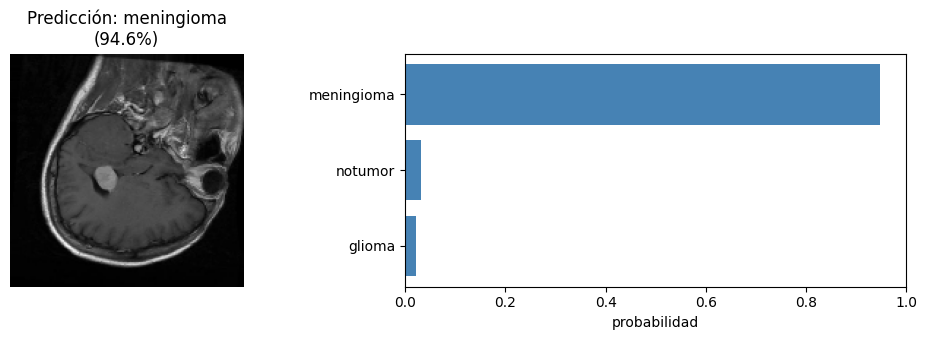

Real: meningioma   | Predicha: meningioma   | ✔


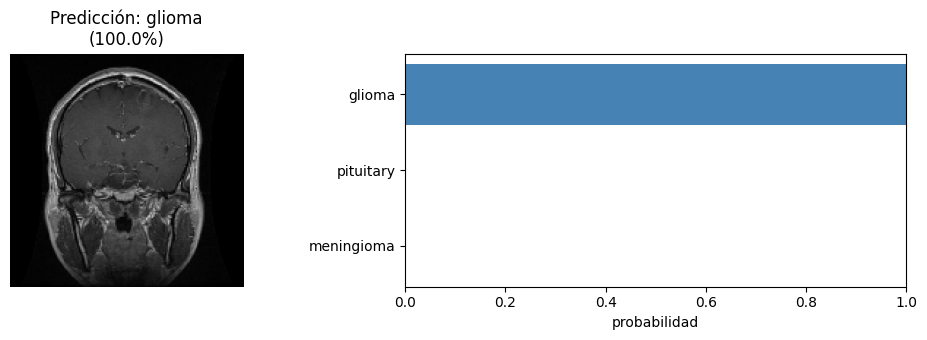

Real: glioma       | Predicha: glioma       | ✔


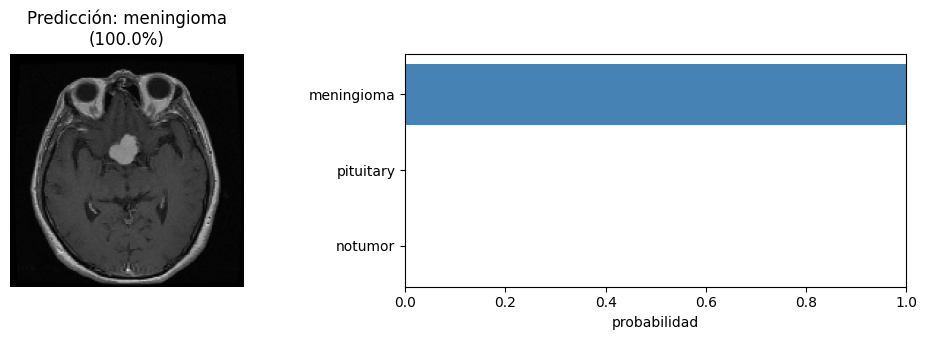

Real: meningioma   | Predicha: meningioma   | ✔


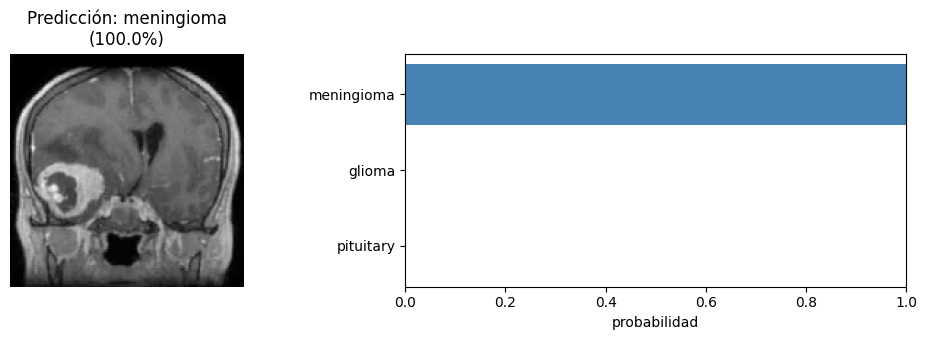

Real: meningioma   | Predicha: meningioma   | ✔


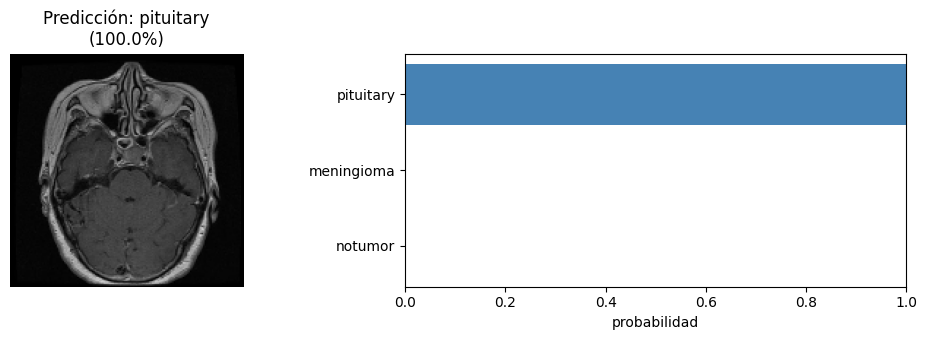

Real: pituitary    | Predicha: pituitary    | ✔


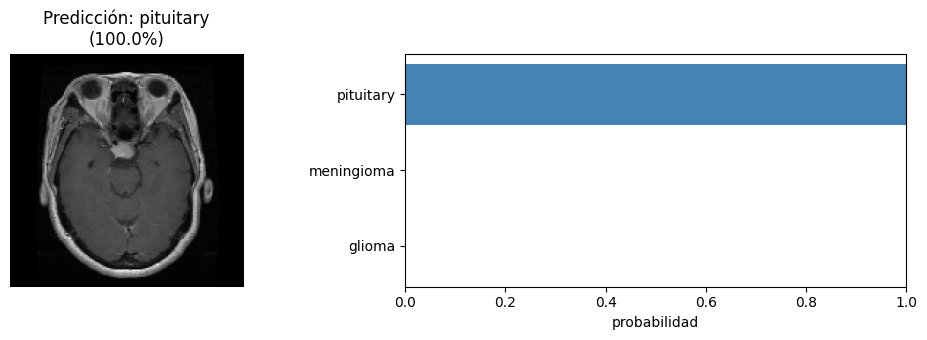

Real: pituitary    | Predicha: pituitary    | ✔

Aciertos en la muestra: 6/6


In [32]:
muestra_test = df_test.sample(6, random_state=7)
aciertos = 0
for _, fila in muestra_test.iterrows():
    r = predecir(fila["ruta"], top_k=3, mostrar=True)
    ok = r["clase"] == fila["clase"]
    aciertos += ok
    print(f"Real: {fila['clase']:12s} | Predicha: {r['clase']:12s} | {'✔' if ok else '✘'}")
print(f"\nAciertos en la muestra: {aciertos}/{len(muestra_test)}")

### Predicciones con imágenes propias
Ejecuta el siguiente código para otras predicciones.
Si trabajas en Colab puedes subir una foto; fuera de Colab basta con llamar `predecir("ruta/a/mi_imagen.jpg")`.

In [ ]:
'''
try:
    from google.colab import files
    subidos = files.upload()
    for nombre in subidos:
        print(nombre)
        print(predecir(nombre, top_k=3))
except ImportError:
    print("No se está ejecutando en Colab. Usa: predecir('ruta/a/mi_imagen.jpg')")
    ejemplo = df_test["ruta"].iloc[0]
    print("Ejemplo con una imagen local:", ejemplo)
    print(predecir(ejemplo, mostrar=False))

'''